# 08 · DL evaluation: XGBoost vs MLP vs hybrid (Phase 2)

This notebook is the final evaluation. It uses **saved predictions only**, so it needs no training and runs in a minute or two.

| Step | Data | Purpose |
|---|---|---|
| 1–2 | Station-split **validation** | Compare the three models; check the blend weight chosen earlier |
| 3 | Station-split **test** | Score once, with 95% station-bootstrap CIs and paired differences |
| 4 | Validation | Where do the models go wrong (country, CCME band, polluted water)? |
| 5 | Year-split test | Secondary check under a different split |

Models: **XGBoost** (Phase 1 saved predictions), **MLP** (30→128→64→1), **Hybrid** (weighted blend of the two, weight chosen on validation only, clipped to 0–100).

The test set was not used to choose anything. The blend weight, the MLP settings and the clipping rule were all fixed on validation first.

In [1]:
import os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
N_BOOT = 2000

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.features import load_final_dataset
from src.hybrid import (XGB_VAL_PATH, XGB_TEST_PATH, XGB_VAL_NAME, XGB_TEST_NAME,
                        load_saved_predictions)

RESULTS = ROOT / "results"
DL = RESULTS / "dl"
FIG = DL / "figures"
FIG.mkdir(parents=True, exist_ok=True)
MODELS = ["XGBoost", "MLP", "Hybrid"]
COLORS = {"XGBoost": "#4C78A8", "MLP": "#F58518", "Hybrid": "#54A24B"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and align the saved predictions

Every file is matched on `row_id`. The code stops if the row IDs or the true targets do not line up.

In [2]:
df = load_final_dataset(str(ROOT / "data/processed/final_dataset.csv"))
meta = df.set_index("row_id")

# ---- validation ----
mlp_val = pd.read_csv(DL / "predictions_mlp_val.csv")
val_ids = mlp_val["row_id"].to_numpy()
y_val = mlp_val["y_true"].to_numpy(dtype=float)
val_preds = {
    "XGBoost": load_saved_predictions(XGB_VAL_PATH, val_ids, model=XGB_VAL_NAME),
    "MLP": mlp_val["y_pred"].to_numpy(dtype=float),
    "Hybrid": load_saved_predictions(RESULTS / "hybrid_val_preds.csv", val_ids),
}
val_sites = meta.loc[val_ids, "site_id"].to_numpy()

# ---- test (station split) ----
mlp_test = pd.read_csv(DL / "predictions_mlp.csv")
test_ids = mlp_test["row_id"].to_numpy()
y_test = mlp_test["y_true"].to_numpy(dtype=float)
xgb_test_file = pd.read_csv(XGB_TEST_PATH)
xgb_test_file = xgb_test_file[xgb_test_file["model"] == XGB_TEST_NAME].set_index("row_id")
assert np.allclose(xgb_test_file.loc[test_ids, "y_true"].to_numpy(), y_test), "test targets differ"
test_preds = {
    "XGBoost": load_saved_predictions(XGB_TEST_PATH, test_ids, model=XGB_TEST_NAME),
    "MLP": mlp_test["y_pred"].to_numpy(dtype=float),
    "Hybrid": load_saved_predictions(RESULTS / "predictions_hybrid.csv", test_ids),
}
test_sites = meta.loc[test_ids, "site_id"].to_numpy()

print(f"Validation: {len(val_ids):,} rows, {len(set(val_sites)):,} stations")
print(f"Test:       {len(test_ids):,} rows, {len(set(test_sites)):,} stations")
print("Stations shared between validation and test:", len(set(val_sites) & set(test_sites)))

Validation: 26,054 rows, 1,136 stations
Test:       51,973 rows, 2,221 stations
Stations shared between validation and test: 0


## 2. Metrics, confidence intervals and paired differences

**Why station-level bootstrap.** Rows from the same station are strongly correlated, so resampling rows would give intervals that are too narrow. We resample whole stations (2,000 draws, seed 42).

**Why paired.** In every draw all three models are scored on the *same* resampled stations. The difference in RMSE between two models is then much more precise than comparing two separate intervals.

In [3]:
def station_tables(y_true, preds, stations):
    codes, uniques = pd.factorize(stations)
    k = len(uniques)
    cnt = np.bincount(codes, minlength=k).astype(float)
    sy = np.bincount(codes, weights=y_true, minlength=k)
    syy = np.bincount(codes, weights=y_true ** 2, minlength=k)
    sae = {m: np.bincount(codes, weights=np.abs(y_true - p), minlength=k) for m, p in preds.items()}
    sse = {m: np.bincount(codes, weights=(y_true - p) ** 2, minlength=k) for m, p in preds.items()}
    return cnt, sy, syy, sae, sse


def point_metrics(y_true, p):
    e = y_true - p
    return {"MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e ** 2))),
            "R2": float(1 - np.sum(e ** 2) / np.sum((y_true - y_true.mean()) ** 2))}


def evaluate(label, y_true, preds, stations, n_boot=N_BOOT, seed=SEED):
    cnt, sy, syy, sae, sse = station_tables(y_true, preds, stations)
    k = len(cnt)
    rng = np.random.default_rng(seed)
    draws = {m: {"MAE": [], "RMSE": [], "R2": []} for m in preds}
    pairs = {("MLP", "XGBoost"): [], ("Hybrid", "XGBoost"): [], ("Hybrid", "MLP"): []}
    for _ in range(n_boot):
        w = np.bincount(rng.integers(0, k, k), minlength=k).astype(float)
        n = w @ cnt
        ss_tot = (w @ syy) - n * ((w @ sy) / n) ** 2
        rm = {}
        for m in preds:
            s = w @ sse[m]
            draws[m]["MAE"].append((w @ sae[m]) / n)
            rm[m] = np.sqrt(s / n)
            draws[m]["RMSE"].append(rm[m])
            draws[m]["R2"].append(1 - s / ss_tot)
        for (a, b), lst in pairs.items():
            lst.append(rm[a] - rm[b])
    ci = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))

    metric_rows, ci_rows, pair_rows = [], [], []
    for m in MODELS:
        pt = point_metrics(y_true, preds[m])
        metric_rows.append({"Model": m, **pt, "Evaluation": label})
        row = {"Model": m, "Evaluation": label}
        for key in ("MAE", "RMSE", "R2"):
            lo, hi = ci(draws[m][key])
            row[key] = pt[key]
            row[f"{key}_CI_Lower"], row[f"{key}_CI_Upper"] = lo, hi
        ci_rows.append(row)
    for (a, b), d in pairs.items():
        lo, hi = ci(d)
        pair_rows.append({"Comparison": f"{a} minus {b} (RMSE)",
                          "Mean_RMSE_Difference": point_metrics(y_true, preds[a])["RMSE"] - point_metrics(y_true, preds[b])["RMSE"],
                          "CI_Lower": lo, "CI_Upper": hi,
                          "CI_excludes_zero": bool(lo > 0 or hi < 0), "Evaluation": label})
    return pd.DataFrame(metric_rows), pd.DataFrame(ci_rows), pd.DataFrame(pair_rows)


val_m, val_ci, val_pair = evaluate("Station-split validation", y_val, val_preds, val_sites)
print("STATION-SPLIT VALIDATION")
display(val_ci.round(3))
display(val_pair.round(4))

STATION-SPLIT VALIDATION


,Model,Evaluation,MAE,MAE_CI_Lower,MAE_CI_Upper,RMSE,RMSE_CI_Lower,RMSE_CI_Upper,R2,R2_CI_Lower,R2_CI_Upper
0,XGBoost,Station-split validation,7.729,7.094,8.446,11.205,10.342,12.164,0.348,0.282,0.398
1,MLP,Station-split validation,7.767,7.118,8.503,11.231,10.374,12.216,0.345,0.280,0.396
2,Hybrid,Station-split validation,7.688,7.045,8.411,11.146,10.286,12.112,0.355,0.289,0.404


,Comparison,Mean_RMSE_Difference,CI_Lower,CI_Upper,CI_excludes_zero,Evaluation
0,MLP minus XGBoost (RMSE),0.0262,-0.0946,0.1436,False,Station-split validation
1,Hybrid minus XGBoost (RMSE),-0.0584,-0.1140,-0.0031,True,Station-split validation
2,Hybrid minus MLP (RMSE),-0.0846,-0.1482,-0.0192,True,Station-split validation


### Blend weight (chosen on validation only)

The hybrid is `w · XGBoost + (1 − w) · MLP`. The weight with the lowest validation RMSE was picked from a grid. Neither model was fitted on validation rows, so ordinary predictions are enough here. Out-of-fold predictions are not needed for a weighted blend. They would only be needed to train a residual model on the training set (see section 6).

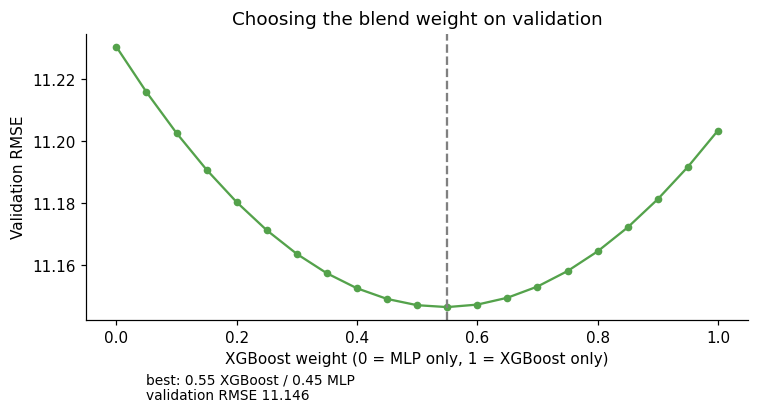

In [4]:
bw = pd.read_csv(RESULTS / "hybrid_blend_weights.csv")
best = bw.loc[bw["rmse"].idxmin()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bw["xgb_weight"], bw["rmse"], marker="o", ms=4, color=COLORS["Hybrid"])
ax.axvline(best["xgb_weight"], ls="--", color="grey")
ax.annotate(f"best: {best['xgb_weight']:.2f} XGBoost / {best['mlp_weight']:.2f} MLP\nvalidation RMSE {best['rmse']:.3f}",
            (best["xgb_weight"], best["rmse"]), xytext=(0.05, best["rmse"] - 0.03), fontsize=9)
ax.set_xlabel("XGBoost weight (0 = MLP only, 1 = XGBoost only)")
ax.set_ylabel("Validation RMSE")
ax.set_title("Choosing the blend weight on validation")
fig.tight_layout()
fig.savefig(FIG / "hybrid_blend_weight_curve.png", dpi=200)
plt.show()

## 3. Station-split test set (scored once)

These are the headline numbers. The test stations were never seen by any model, and nothing below was used to change a model.

In [5]:
test_m, test_ci, test_pair = evaluate("Station-split test", y_test, test_preds, test_sites)
print("STATION-SPLIT TEST")
display(test_ci.round(3))
display(test_pair.round(4))

STATION-SPLIT TEST


,Model,Evaluation,MAE,MAE_CI_Lower,MAE_CI_Upper,RMSE,RMSE_CI_Lower,RMSE_CI_Upper,R2,R2_CI_Lower,R2_CI_Upper
0,XGBoost,Station-split test,7.543,7.044,8.018,11.058,10.309,11.819,0.293,0.244,0.341
1,MLP,Station-split test,7.606,7.099,8.088,11.108,10.366,11.863,0.287,0.236,0.336
2,Hybrid,Station-split test,7.521,7.013,7.998,11.010,10.263,11.772,0.300,0.249,0.347


,Comparison,Mean_RMSE_Difference,CI_Lower,CI_Upper,CI_excludes_zero,Evaluation
0,MLP minus XGBoost (RMSE),0.0491,-0.0534,0.1470,False,Station-split test
1,Hybrid minus XGBoost (RMSE),-0.0486,-0.0984,-0.0022,True,Station-split test
2,Hybrid minus MLP (RMSE),-0.0977,-0.1502,-0.0431,True,Station-split test


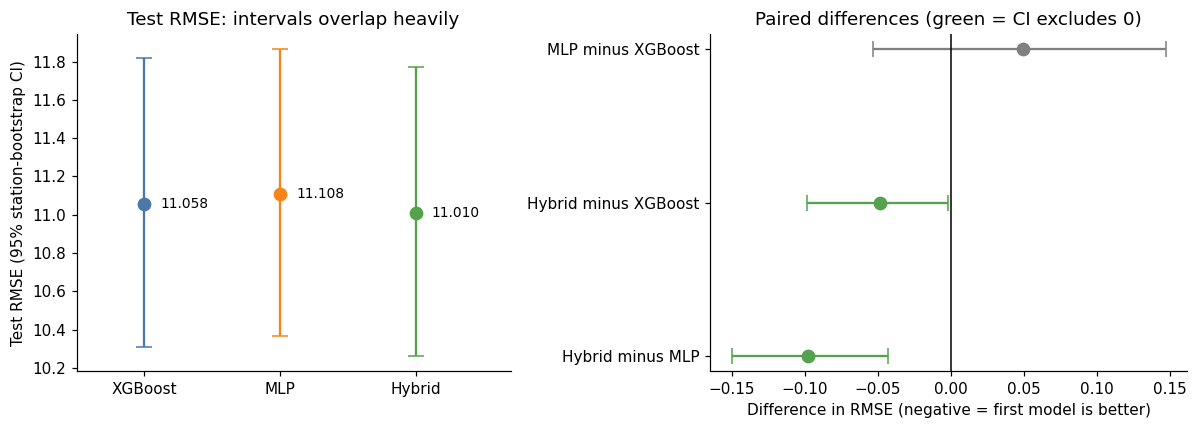

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.1]})

ax = axes[0]
for i, m in enumerate(MODELS):
    r = test_ci[test_ci["Model"] == m].iloc[0]
    ax.errorbar(i, r["RMSE"], yerr=[[r["RMSE"] - r["RMSE_CI_Lower"]], [r["RMSE_CI_Upper"] - r["RMSE"]]],
                fmt="o", color=COLORS[m], capsize=5, ms=8)
    ax.text(i + 0.12, r["RMSE"], f"{r['RMSE']:.3f}", va="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(MODELS); ax.set_xlim(-0.5, 2.7)
ax.set_ylabel("Test RMSE (95% station-bootstrap CI)")
ax.set_title("Test RMSE: intervals overlap heavily")

ax = axes[1]
labels = test_pair["Comparison"].str.replace(" (RMSE)", "", regex=False)
for i, r in test_pair.iterrows():
    c = "#54A24B" if r["CI_excludes_zero"] else "grey"
    ax.errorbar(r["Mean_RMSE_Difference"], i, xerr=[[r["Mean_RMSE_Difference"] - r["CI_Lower"]], [r["CI_Upper"] - r["Mean_RMSE_Difference"]]],
                fmt="o", color=c, capsize=5, ms=8)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(range(len(test_pair))); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlabel("Difference in RMSE (negative = first model is better)")
ax.set_title("Paired differences (green = CI excludes 0)")
fig.tight_layout()
fig.savefig(FIG / "station_test_rmse_and_paired_differences.png", dpi=200)
plt.show()

**Reading the test result.**

- The hybrid has the lowest test RMSE, 11.010, against 11.058 for XGBoost and 11.108 for the MLP.
- Hybrid vs MLP: −0.098 RMSE, and the interval excludes zero. Blending clearly helps the MLP.
- Hybrid vs XGBoost: −0.049 RMSE with CI [−0.098, −0.002]. The interval only just excludes zero, so this is a **small** gain, not a large one. The blend weight was chosen on validation and this gain is on separate test stations, so it is not circular, but it is still a small effect.
- MLP vs XGBoost: +0.049 RMSE and the interval includes zero. **We cannot say the MLP is better or worse than XGBoost** on these test stations.
- All R² values are low (about 0.29–0.30). The target is capped at 100 and many stations are hard to predict from three sensor readings, so no model fits well.

In [7]:
metrics_dl = pd.concat([val_m, test_m], ignore_index=True)

# Year-split secondary check (section 5), kept in the same table.
ys = pd.read_csv(DL / "year_split_test_metrics.csv").rename(columns={"mae": "MAE", "rmse": "RMSE", "r2": "R2"})
ys["Evaluation"] = "Year-split test"
metrics_dl = pd.concat([metrics_dl, ys[["Model", "MAE", "RMSE", "R2", "Evaluation"]]], ignore_index=True)

metrics_dl.to_csv(DL / "metrics_dl.csv", index=False)
pd.concat([val_ci, test_ci], ignore_index=True).to_csv(DL / "station_bootstrap_ci.csv", index=False)
pd.concat([val_pair, test_pair], ignore_index=True).to_csv(DL / "paired_rmse_differences.csv", index=False)
val_m[["Model", "MAE", "RMSE", "R2"]].to_csv(DL / "validation_metrics.csv", index=False)

display(metrics_dl.round(4))

,Model,MAE,RMSE,R2,Evaluation
0,XGBoost,7.7292,11.2048,0.3478,Station-split validation
1,MLP,7.7673,11.2311,0.3447,Station-split validation
2,Hybrid,7.6876,11.1465,0.3546,Station-split validation
3,XGBoost,7.5435,11.0585,0.2933,Station-split test
4,MLP,7.6062,11.1075,0.2870,Station-split test
5,Hybrid,7.5214,11.0098,0.2995,Station-split test
6,XGBoost,5.4692,8.0605,0.2399,Year-split test
7,MLP,5.2775,7.8659,0.2761,Year-split test
8,Hybrid,5.3007,7.8421,0.2805,Year-split test


## 4. Where do the models go wrong? (validation)

This is descriptive. It is done on validation so the test set stays untouched. `Mean_Error` is prediction minus truth, so a positive value means over-prediction.

In [8]:
err = pd.DataFrame({"row_id": val_ids, "y_true": y_val,
                    "country": meta.loc[val_ids, "country"].to_numpy(),
                    "target_ccme_class": meta.loc[val_ids, "target_ccme_class"].to_numpy()})
for m in MODELS:
    err[f"{m}_error"] = val_preds[m] - y_val


def grouped(data, col):
    rows = []
    for g, grp in data.groupby(col):
        for m in MODELS:
            e = grp[f"{m}_error"].to_numpy()
            rows.append({col: g, "Model": m, "Rows": len(grp), "MAE": np.mean(np.abs(e)),
                         "RMSE": np.sqrt(np.mean(e ** 2)), "Mean_Error": np.mean(e)})
    return pd.DataFrame(rows)


country_errors = grouped(err, "country")
band_errors = grouped(err, "target_ccme_class")
country_errors.to_csv(DL / "country_error_analysis.csv", index=False)
band_errors.to_csv(DL / "ccme_band_error_analysis.csv", index=False)

print("BY COUNTRY (RMSE)")
display(country_errors.pivot(index="country", columns="Model", values="RMSE")[MODELS].round(2))
print("BY CCME CLASS (mean error: prediction minus truth)")
display(band_errors.pivot(index="target_ccme_class", columns="Model", values="Mean_Error")[MODELS].round(2))

BY COUNTRY (RMSE)


Model,XGBoost,MLP,Hybrid
country,,,
Canada,10.03,10.24,10.00
England,12.47,12.51,12.42
Ireland,6.01,5.95,5.92
USA,3.62,3.69,3.50


BY CCME CLASS (mean error: prediction minus truth)


Model,XGBoost,MLP,Hybrid
target_ccme_class,,,
Excellent,-5.78,-5.89,-5.84
Fair,10.23,10.46,10.33
Good,-1.46,-1.18,-1.33
Marginal,25.28,25.19,25.24
Poor,35.73,34.95,35.38


Polluted water (true CCME < 60): 1,755 rows, 6.7% of validation


,Model,Rows,MAE,RMSE,Mean_Error,Overprediction_Rate,Mean_Prediction,Mean_Actual
0,XGBoost,1755,29.124,30.221,29.124,100.000,79.583,50.459
1,MLP,1755,28.897,30.096,28.897,99.943,79.356,50.459
2,Hybrid,1755,29.022,30.115,29.022,100.000,79.481,50.459


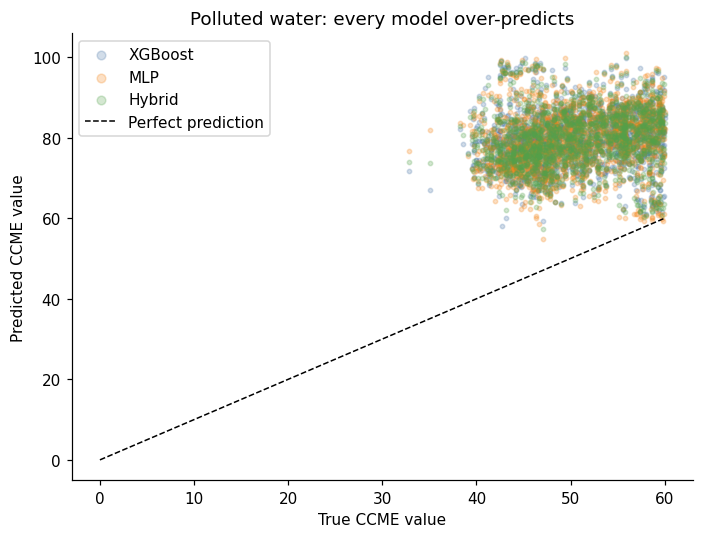

In [9]:
poll = err[err["y_true"] < 60]
rows = []
for m in MODELS:
    e = poll[f"{m}_error"].to_numpy()
    p = e + poll["y_true"].to_numpy()
    rows.append({"Model": m, "Rows": len(poll), "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
                 "Mean_Error": np.mean(e), "Overprediction_Rate": 100 * np.mean(e > 0),
                 "Mean_Prediction": p.mean(), "Mean_Actual": poll["y_true"].mean()})
polluted = pd.DataFrame(rows)
polluted.to_csv(DL / "polluted_water_error_analysis.csv", index=False)
print(f"Polluted water (true CCME < 60): {len(poll):,} rows, {100 * len(poll) / len(err):.1f}% of validation")
display(polluted.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5))
for m in MODELS:
    ax.scatter(poll["y_true"], poll[f"{m}_error"] + poll["y_true"], s=8, alpha=0.25, color=COLORS[m], label=m)
ax.plot([0, 60], [0, 60], "k--", lw=1, label="Perfect prediction")
ax.set_xlabel("True CCME value"); ax.set_ylabel("Predicted CCME value")
ax.set_title("Polluted water: every model over-predicts")
ax.legend(markerscale=2)
fig.tight_layout()
fig.savefig(FIG / "polluted_water_pred_vs_actual.png", dpi=200)
plt.show()

**Reading this.** On polluted samples (true CCME below 60) all three models over-predict: they predict roughly 80 where the truth averages about 50. They are trained to minimise average error, and most samples are clean (many exactly 100), so they are pulled toward the high values. The blend does not fix this. This is the main weakness of the whole approach.

## 5. Secondary check: year-based split

A second split trains on earlier years and tests on later years (`split_time`). The predictions below were produced once and saved. Set `RUN_YEAR_SPLIT_TRAINING = True` in the next cell to retrain and regenerate them (needs `torch` and `xgboost`, takes several minutes). The 50:50 blend weight was used on this split.

In [10]:
RUN_YEAR_SPLIT_TRAINING = False
RUN_RESIDUAL_DIAGNOSTIC = False

In [11]:
# Retrain the year-split models and regenerate the saved predictions.
if RUN_YEAR_SPLIT_TRAINING:
    # Cell 25: Load temporal split data

    from src.dl_data import load_dl_data

    time_data = load_dl_data(split_col="split_time")

    print("Temporal split loaded successfully.\n")

    for key, value in time_data.items():
        if isinstance(value, np.ndarray):
            print(f"{key}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"{key}: {value}")

    # Cell 27: Prepare temporal MLP training data

    time_mlp_data = {
        "X_train": time_data["X_train"],
        "y_train": time_data["y_train"],
        "X_val": time_data["X_val"],
        "y_val": time_data["y_val"],
    }

    print("Temporal MLP training data prepared.")

    print("Training features:", time_mlp_data["X_train"].shape)
    print("Training targets:", time_mlp_data["y_train"].shape)
    print("Validation features:", time_mlp_data["X_val"].shape)
    print("Validation targets:", time_mlp_data["y_val"].shape)

    # Cell 28: Train MLP using the temporal split

    from src.train_dl import train_one, default_cfg

    time_mlp_cfg = default_cfg()

    time_mlp_model, time_y_mean, time_y_std, time_best_epoch, time_mlp_history = train_one(
        time_mlp_data,
        time_mlp_cfg,
        max_epochs=60,
        verbose=True
    )

    print("\n===== TEMPORAL MLP TRAINING SUMMARY =====")
    print("Best epoch:", time_best_epoch)
    print("Target mean:", time_y_mean)
    print("Target standard deviation:", time_y_std)
    print("Configuration:", time_mlp_cfg)

    # Cell 29: Generate temporal MLP validation predictions

    from src.train_dl import predict, regression_metrics

    time_mlp_val_pred = predict(
        time_mlp_model,
        time_data["X_val"],
        time_y_mean,
        time_y_std
    )

    time_mlp_metrics = regression_metrics(
        time_data["y_val"],
        time_mlp_val_pred
    )

    print("===== TEMPORAL MLP VALIDATION RESULTS =====")
    print("MAE:", time_mlp_metrics["mae"])
    print("RMSE:", time_mlp_metrics["rmse"])
    print("R²:", time_mlp_metrics["r2"])

    print("\nPrediction range:")
    print("Minimum:", time_mlp_val_pred.min())
    print("Maximum:", time_mlp_val_pred.max())

    # Cell 34: Train XGBoost on already-preprocessed temporal features

    from xgboost import XGBRegressor

    time_xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.03,
        objective="reg:squarederror",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=1,
        tree_method="hist",
        verbosity=0
    )

    time_xgb_model.fit(
        time_data["X_train"],
        time_data["y_train"]
    )

    print("Temporal XGBoost training completed.")

    # Cell 35: Evaluate temporal XGBoost and MLP on validation data

    from src.train_dl import regression_metrics, predict
    import pandas as pd

    # XGBoost validation predictions
    time_xgb_val_pred = time_xgb_model.predict(
        time_data["X_val"]
    )

    # MLP validation predictions
    time_mlp_val_pred = predict(
        time_mlp_model,
        time_data["X_val"],
        time_y_mean,
        time_y_std
    )

    # Compare both models
    time_val_results = []

    for model_name, predictions in [
        ("XGBoost", time_xgb_val_pred),
        ("MLP", time_mlp_val_pred)
    ]:
        metrics = regression_metrics(
            time_data["y_val"],
            predictions
        )

        time_val_results.append({
            "Model": model_name,
            **metrics
        })

    time_val_metrics = pd.DataFrame(time_val_results)

    display(time_val_metrics)

    print("Temporal validation comparison completed.")

    # Cell 36: Select the best temporal hybrid blend using validation data

    import numpy as np
    import pandas as pd
    from src.train_dl import regression_metrics

    y_val = time_data["y_val"]

    blend_results = []

    # Test XGBoost weights from 0% to 100%
    for xgb_weight in np.arange(0, 1.01, 0.05):
        mlp_weight = 1 - xgb_weight

        blend_pred = (
            xgb_weight * time_xgb_val_pred
            + mlp_weight * time_mlp_val_pred
        )

        metrics = regression_metrics(y_val, blend_pred)

        blend_results.append({
            "xgb_weight": round(float(xgb_weight), 2),
            "mlp_weight": round(float(mlp_weight), 2),
            **metrics
        })

    blend_results_df = pd.DataFrame(blend_results)

    # Select the blend with the lowest validation RMSE
    best_blend = blend_results_df.loc[
        blend_results_df["rmse"].idxmin()
    ]

    best_time_xgb_weight = float(best_blend["xgb_weight"])
    best_time_mlp_weight = float(best_blend["mlp_weight"])

    print("Best temporal blend:")
    display(best_blend.to_frame().T)

    print(
        f"Selected weights: XGBoost={best_time_xgb_weight:.2f}, "
        f"MLP={best_time_mlp_weight:.2f}"
    )

    print("\nAll tested blend weights:")
    display(blend_results_df)

    # Cell 42: Save selected temporal validation predictions

    from pathlib import Path
    import pandas as pd
    from src.hybrid import clip_predictions

    time_hybrid_val_pred = (
        0.50 * time_xgb_val_pred
        + 0.50 * time_mlp_val_pred
    )

    time_val_export = pd.DataFrame({
        "row_id": time_data["row_id_val"],
        "y_true": time_data["y_val"],
        "xgb_pred": clip_predictions(time_xgb_val_pred, 0, 100),
        "mlp_pred": clip_predictions(time_mlp_val_pred, 0, 100),
        "hybrid_pred": clip_predictions(time_hybrid_val_pred, 0, 100)
    })

    output_dir = ROOT / "results" / "dl"
    output_dir.mkdir(parents=True, exist_ok=True)

    time_val_export.to_csv(
        output_dir / "year_split_validation_predictions.csv",
        index=False
    )

    print("Saved temporal validation predictions.")
    print("Rows:", len(time_val_export))
    display(time_val_export.head())

    # Cell 43: Final temporal test evaluation

    from src.hybrid import clip_predictions
    from src.train_dl import regression_metrics

    # Generate test predictions
    time_xgb_test_pred = time_xgb_model.predict(
        time_data["X_test"]
    )

    time_mlp_test_pred = predict(
        time_mlp_model,
        time_data["X_test"],
        time_y_mean,
        time_y_std
    )

    # Selected 50:50 blend
    time_hybrid_test_pred = (
        0.50 * time_xgb_test_pred
        + 0.50 * time_mlp_test_pred
    )

    # Apply the validation-selected clipping rule consistently
    test_predictions = {
        "XGBoost": clip_predictions(time_xgb_test_pred, 0, 100),
        "MLP": clip_predictions(time_mlp_test_pred, 0, 100),
        "Hybrid": clip_predictions(time_hybrid_test_pred, 0, 100)
    }

    # Final test metrics
    test_results = []

    for model_name, predictions in test_predictions.items():
        metrics = regression_metrics(
            time_data["y_test"],
            predictions
        )

        test_results.append({
            "Model": model_name,
            **metrics
        })

    year_test_metrics = pd.DataFrame(test_results)

    display(year_test_metrics)

    # Save final predictions
    time_test_export = pd.DataFrame({
        "row_id": time_data["row_id_test"],
        "y_true": time_data["y_test"],
        "xgb_pred": test_predictions["XGBoost"],
        "mlp_pred": test_predictions["MLP"],
        "hybrid_pred": test_predictions["Hybrid"]
    })

    time_test_export.to_csv(
        output_dir / "year_split_test_predictions.csv",
        index=False
    )

    year_test_metrics.to_csv(
        output_dir / "year_split_test_metrics.csv",
        index=False
    )

    print("\nFinal temporal test evaluation completed.")
    print("Test rows:", len(time_test_export))
    print("Prediction files saved in:", output_dir)

In [12]:
ys = pd.read_csv(DL / "year_split_test_metrics.csv")
ys.columns = [c.upper() if c.lower() in ("mae", "rmse", "r2") else c for c in ys.columns]
print("YEAR-SPLIT TEST (point estimates, no confidence intervals)")
display(ys.round(4))
for name in ("year_split_country_error_analysis", "year_split_ccme_class_error_analysis", "year_split_polluted_water_analysis"):
    print(name)
    display(pd.read_csv(DL / f"{name}.csv").round(3))

YEAR-SPLIT TEST (point estimates, no confidence intervals)


,Model,MAE,RMSE,R2
0,XGBoost,5.4692,8.0605,0.2399
1,MLP,5.2775,7.8659,0.2761
2,Hybrid,5.3007,7.8421,0.2805


year_split_country_error_analysis


,Country,Model,Rows,mae,rmse,r2,Mean_Error
0,Canada,XGBoost,1075,7.308,11.915,0.011,3.108
1,Canada,MLP,1075,7.607,12.450,-0.080,4.540
2,Canada,Hybrid,1075,7.342,12.130,-0.025,3.824
3,England,XGBoost,25527,7.582,9.904,0.167,-2.514
4,England,MLP,25527,7.617,9.981,0.154,-2.037
5,England,Hybrid,25527,7.538,9.835,0.179,-2.275
6,Ireland,XGBoost,23478,3.425,5.662,-0.770,-1.372
7,Ireland,MLP,23478,2.955,4.764,-0.253,-0.752
8,Ireland,Hybrid,23478,3.113,5.049,-0.407,-0.997
9,USA,XGBoost,3101,2.919,3.868,0.190,-1.883


year_split_ccme_class_error_analysis


,CCME_Class,Model,Rows,mae,rmse,r2,Mean_Error
0,Excellent,XGBoost,30033,4.682,6.961,0.000,-4.682
1,Excellent,MLP,30033,4.313,6.233,0.000,-4.313
2,Excellent,Hybrid,30033,4.451,6.466,0.000,-4.451
3,Fair,XGBoost,2912,10.541,12.321,-7.634,9.919
4,Fair,MLP,2912,11.703,13.295,-9.053,11.205
5,Fair,Hybrid,2912,11.061,12.710,-8.187,10.564
6,Good,XGBoost,19038,4.716,6.110,-2.168,-0.891
7,Good,MLP,19038,4.467,5.837,-1.891,-0.252
8,Good,Hybrid,19038,4.470,5.825,-1.879,-0.562
9,Marginal,XGBoost,1133,24.024,25.595,-21.332,24.021


year_split_polluted_water_analysis


,Model,Rows,mae,rmse,r2,Mean_Error,Overprediction_Rate,Mean_Prediction,Mean_Actual
0,XGBoost,766,27.924,29.363,-34.445,27.924,100.0,80.761,52.837
1,MLP,766,29.836,31.185,-38.983,29.836,100.0,82.673,52.837
2,Hybrid,766,28.881,30.208,-36.516,28.881,100.0,81.719,52.837


**Reading this.** On the year split the MLP and the hybrid both beat XGBoost on RMSE (7.87 and 7.84 against 8.06). This is one split with no confidence interval, so treat it as supporting evidence only. The ranking is not the same as on the station split, where the models are statistically hard to separate.

## 6. Residual-learning hybrid (tried and rejected)

We also tried a residual hybrid: an MLP trained to predict XGBoost's remaining error. **This is the one place out-of-fold (OOF) predictions are needed.** XGBoost's predictions on its own training rows are too good, so the residuals would be too small. We use 5-fold station-grouped OOF predictions to build honest residual targets.

It was not selected. The residual MLP's predicted corrections had almost no correlation with the true residuals: about 0.088 on the station split and about −0.001 on the year split. So the correction carried no useful signal. The saved numbers come from the earlier run of this experiment. Set `RUN_RESIDUAL_DIAGNOSTIC = True` (and `RUN_YEAR_SPLIT_TRAINING = True`) to repeat the year-split version.

In [13]:
if RUN_RESIDUAL_DIAGNOSTIC:
    # Cell 38: Generate station-grouped OOF predictions for temporal XGBoost

    import numpy as np
    from sklearn.model_selection import GroupKFold
    from xgboost import XGBRegressor

    X_train = time_data["X_train"]
    y_train = time_data["y_train"]
    groups_train = time_data["groups_train"]

    oof_xgb_pred = np.zeros(len(y_train), dtype=np.float32)

    gkf = GroupKFold(n_splits=5)

    for fold, (train_idx, valid_idx) in enumerate(
        gkf.split(X_train, y_train, groups=groups_train), start=1
    ):
        fold_model = XGBRegressor(
            n_estimators=300,
            max_depth=8,
            learning_rate=0.03,
            objective="reg:squarederror",
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=1,
            tree_method="hist",
            verbosity=0
        )

        fold_model.fit(
            X_train[train_idx],
            y_train[train_idx]
        )

        oof_xgb_pred[valid_idx] = fold_model.predict(
            X_train[valid_idx]
        )

        fold_rmse = np.sqrt(
            np.mean(
                (y_train[valid_idx] - oof_xgb_pred[valid_idx]) ** 2
            )
        )

        print(f"Fold {fold} RMSE: {fold_rmse:.4f}")

    assert np.isfinite(oof_xgb_pred).all()

    print("\nOOF predictions generated:", len(oof_xgb_pred))
    print("OOF prediction range:", oof_xgb_pred.min(), "to", oof_xgb_pred.max())

    # Cell 39: Prepare residual-learning targets

    # Training residuals from station-grouped OOF predictions
    time_residual_train = y_train - oof_xgb_pred

    # Validation residuals from the XGBoost model trained on all temporal training data
    time_residual_val = (
        time_data["y_val"] - time_xgb_val_pred
    )

    # Prepare data for the residual MLP
    time_residual_data = {
        "X_train": time_data["X_train"],
        "y_train": time_residual_train,
        "X_val": time_data["X_val"],
        "y_val": time_residual_val
    }

    print("Residual target preparation completed.")
    print("\nTraining residuals:")
    print("Mean:", np.mean(time_residual_train))
    print("Standard deviation:", np.std(time_residual_train))
    print("Minimum:", np.min(time_residual_train))
    print("Maximum:", np.max(time_residual_train))

    print("\nValidation residuals:")
    print("Mean:", np.mean(time_residual_val))
    print("Standard deviation:", np.std(time_residual_val))

    assert np.isfinite(time_residual_train).all()
    assert np.isfinite(time_residual_val).all()

    # Cell 40: Train residual MLP

    from src.train_dl import train_one, default_cfg

    time_residual_cfg = default_cfg()

    (
        time_residual_model,
        time_residual_y_mean,
        time_residual_y_std,
        time_residual_best_epoch,
        time_residual_history
    ) = train_one(
        time_residual_data,
        time_residual_cfg,
        max_epochs=60,
        verbose=True
    )

    print("\nResidual MLP training completed.")
    print("Best epoch:", time_residual_best_epoch)
    print("Residual target mean:", time_residual_y_mean)
    print("Residual target standard deviation:", time_residual_y_std)

    # Cell 41: Evaluate residual-learning hybrid

    from src.train_dl import predict, regression_metrics
    from src.hybrid import clip_predictions

    # Predict residual corrections
    time_residual_correction = predict(
        time_residual_model,
        time_data["X_val"],
        time_residual_y_mean,
        time_residual_y_std
    )

    # Add corrections to full-training XGBoost predictions
    time_residual_hybrid_pred = (
        time_xgb_val_pred + time_residual_correction
    )

    # Existing 50:50 blend
    time_blend_pred = (
        0.50 * time_xgb_val_pred
        + 0.50 * time_mlp_val_pred
    )

    # Compare all approaches
    comparison_models = {
        "XGBoost": time_xgb_val_pred,
        "MLP": time_mlp_val_pred,
        "Blending (50:50)": time_blend_pred,
        "Residual Learning": time_residual_hybrid_pred
    }

    residual_comparison = []

    for model_name, raw_pred in comparison_models.items():

        clipped_pred = clip_predictions(
            raw_pred,
            lower=0,
            upper=100
        )

        metrics = regression_metrics(
            time_data["y_val"],
            clipped_pred
        )

        residual_comparison.append({
            "Model": model_name,
            **metrics
        })

    residual_comparison_df = pd.DataFrame(residual_comparison)

    display(
        residual_comparison_df.sort_values("rmse")
    )

    print("\nResidual correction diagnostics:")
    print("Mean correction:", np.mean(time_residual_correction))
    print("Correction standard deviation:", np.std(time_residual_correction))
    print("Correction correlation with actual residual:",
          np.corrcoef(time_residual_correction, time_residual_val)[0, 1])